# Naive Bayes March Machine Learning Mania 2026

This notebook follows the shared protocol in the README:

- **Expanding-window temporal CV** on validation seasons 2017, 2018, 2019 and 2021 (train on all earlier tournament seasons).
- **Metric:** Brier score on the predicted probability that Team1 wins (lower is better).
- **Holdout:** 2022–2025, trained on seasons up to 2021. Run **once**, for the final configuration only.

Structure:

1. Load data and build all feature columns (Elo merge, Log Massey)
2. Why Naive Bayes struggles here: feature correlation
3. Round 1 — plain Gaussian NB on the agreed feature stages (S1–S5)
4. Round 2 — new features (Net Rating, Adjusted Strength)
5. Ablation A — probability calibration (Platt / isotonic)
6. Ablation B — PCA decorrelation before NB
7. Summary table and final configuration
8. 2022–2025 holdout (diagnostic only)

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss

DATA = Path("../data/processed")
RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)

VALIDATION_YEARS = [2017, 2018, 2019, 2021]
HOLDOUT_YEARS = [2022, 2023, 2024, 2025]
RANDOM_STATE = 42

## 1. Load data and build features

`men_advanced_merged.csv` / `women_advanced_merged.csv` already hold the original four features plus Net Rating and Adjusted Strength. Elo is merged on from the team-season files (README §4.2), and the men's Massey ranks from `men_massey.csv`, from which `LogMasseyRankDiff` is computed (README §5.3).

All features follow `Team1 - Team2`.

In [4]:
def merge_elo(df, gender):
    elo = pd.read_csv(DATA / f"{gender}_elo.csv")
    for side in ["Team1", "Team2"]:
        df = df.merge(
            elo.rename(columns={"TeamID": side, "FinalElo": f"{side}Elo"}),
            on=["Season", side], how="left", validate="many_to_one",
        )
    assert df[["Team1Elo", "Team2Elo"]].notna().all().all(), "missing Elo"
    df["EloDiff"] = df["Team1Elo"] - df["Team2Elo"]
    return df


def load(gender):
    df = pd.read_csv(DATA / f"{gender}_advanced_merged.csv")
    df = merge_elo(df, gender)
    if gender == "men":
        massey = pd.read_csv(DATA / "men_massey.csv")[
            ["Season", "Team1", "Team2", "Team1MasseyRank", "Team2MasseyRank", "MasseyRankDiff"]
        ]
        df = df.merge(massey, on=["Season", "Team1", "Team2"], how="left", validate="one_to_one")
        assert df["MasseyRankDiff"].notna().all(), "missing Massey"
        df["LogMasseyRankDiff"] = np.log(df["Team1MasseyRank"]) - np.log(df["Team2MasseyRank"])
    return df


men = load("men")
women = load("women")
print("Men:", men.shape, men["Season"].min(), "-", men["Season"].max())
print("Women:", women.shape, women["Season"].min(), "-", women["Season"].max())

Men: (1449, 21) 2003 - 2025
Women: (961, 17) 2010 - 2025


In [5]:
BASE = ["SeedDiff", "AvgScoringMarginDiff", "WinRateDiff", "EFGDifferentialDiff"]

FEATURE_SETS = {
    "men": {
        "S1 base":            BASE,
        "S2 base+Elo":        BASE + ["EloDiff"],
        "S3 base+Massey+Elo": BASE + ["MasseyRankDiff", "EloDiff"],
        "S4 base+Massey":     BASE + ["MasseyRankDiff"],
        "S5 base+LogMassey":  BASE + ["LogMasseyRankDiff"],
    },
    "women": {
        "S1 base":     BASE,
        "S2 base+Elo": BASE + ["EloDiff"],
    },
}

# Round 2: the newer features JW pushed (README §4.4–4.5)
NEW_FEATURE_SETS = {
    "men": {
        "base+NetRating":               BASE + ["NetRatingDiff"],
        "NetRating replaces Margin":    ["SeedDiff", "NetRatingDiff", "WinRateDiff", "EFGDifferentialDiff"],
        "base+AdjStrength":             BASE + ["AdjustedStrengthDiff"],
        "base+LogMassey+AdjStrength":   BASE + ["LogMasseyRankDiff", "AdjustedStrengthDiff"],
    },
    "women": {
        "base+NetRating":               BASE + ["NetRatingDiff"],
        "NetRating replaces Margin":    ["SeedDiff", "NetRatingDiff", "WinRateDiff", "EFGDifferentialDiff"],
        "base+AdjStrength":             BASE + ["AdjustedStrengthDiff"],
    },
}
DATASETS = {"men": men, "women": women}

## 2. Why Naive Bayes struggles here: feature correlation

Gaussian NB assumes features are **conditionally independent** given the class. Our features all measure "how much stronger is Team1", so they are strongly correlated. NB then multiplies the same evidence several times and produces **overconfident** probabilities, which the Brier score penalises heavily.

This motivates the two ablations later: calibration (fix the probabilities after the fact) and PCA decorrelation (remove the correlation before NB sees it).

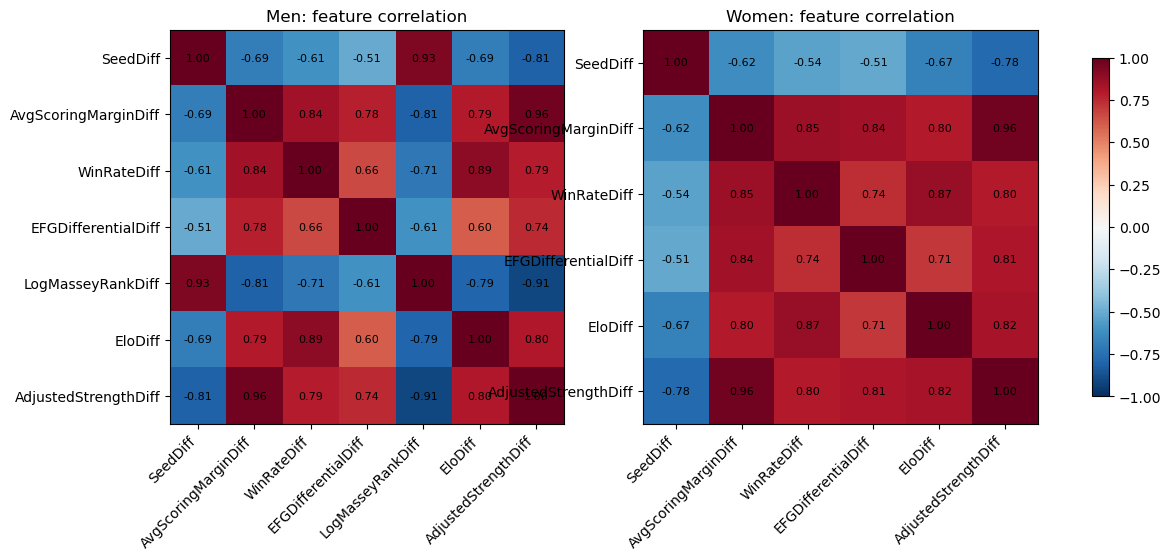

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (gender, cols) in zip(axes, [
    ("men", BASE + ["LogMasseyRankDiff", "EloDiff", "AdjustedStrengthDiff"]),
    ("women", BASE + ["EloDiff", "AdjustedStrengthDiff"]),
]):
    corr = DATASETS[gender][cols].corr()
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
    ax.set_yticks(range(len(cols)), cols)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{gender.capitalize()}: feature correlation")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.savefig(RESULTS / "nb_feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

## CV helper

Fresh model per fold, trained only on seasons before the validation season. Returns per-season and mean Brier.

In [7]:
def temporal_cv(df, features, make_model, years=VALIDATION_YEARS):
    per_season = {}
    for year in years:
        train = df[df["Season"] < year]
        valid = df[df["Season"] == year]
        model = make_model()
        model.fit(train[features], train["Target"])
        prob = model.predict_proba(valid[features])[:, 1]
        per_season[year] = brier_score_loss(valid["Target"], prob)
    per_season["Mean"] = float(np.mean([per_season[y] for y in years]))
    return per_season


ALL_RESULTS = []

def run(gender, feature_sets, models, stage):
    rows = []
    for set_name, feats in feature_sets.items():
        for model_name, make_model in models.items():
            res = temporal_cv(DATASETS[gender], feats, make_model)
            row = {"Gender": gender, "Stage": stage, "FeatureSet": set_name,
                   "Model": model_name, "NFeatures": len(feats), **res}
            rows.append(row)
    ALL_RESULTS.extend(rows)
    out = pd.DataFrame(rows).set_index(["FeatureSet", "Model"])
    cols = VALIDATION_YEARS + ["Mean"]
    return out[cols].round(4)

## 3. Round 1 — plain Gaussian NB on the agreed stages

In [8]:
PLAIN = {"GaussianNB": lambda: GaussianNB()}

print("MEN")
display(run("men", FEATURE_SETS["men"], PLAIN, "Round 1"))
print("WOMEN")
display(run("women", FEATURE_SETS["women"], PLAIN, "Round 1"))

MEN


,,2017,2018,2019,2021,Mean
FeatureSet,Model,,,,,
S1 base,GaussianNB,0.2331,0.2419,0.2258,0.2886,0.2474
S2 base+Elo,GaussianNB,0.2427,0.2478,0.2355,0.3164,0.2606
S3 base+Massey+Elo,GaussianNB,0.2362,0.2386,0.2311,0.3154,0.2553
S4 base+Massey,GaussianNB,0.2294,0.2377,0.2205,0.2904,0.2445
S5 base+LogMassey,GaussianNB,0.2234,0.2456,0.2279,0.2943,0.2478


WOMEN


,,2017,2018,2019,2021,Mean
FeatureSet,Model,,,,,
S1 base,GaussianNB,0.1761,0.2056,0.1653,0.2254,0.1931
S2 base+Elo,GaussianNB,0.1883,0.2131,0.1705,0.2628,0.2087


**Single-feature check.** If correlation is the problem, a model using just one strong feature should do *better* than the full set, since there is nothing to double-count.

In [9]:
SINGLE = {
    "men": {f"{f} only": [f] for f in ["SeedDiff", "LogMasseyRankDiff", "AvgScoringMarginDiff"]},
    "women": {f"{f} only": [f] for f in ["SeedDiff", "AvgScoringMarginDiff"]},
}
print("MEN")
display(run("men", SINGLE["men"], PLAIN, "Single feature"))
print("WOMEN")
display(run("women", SINGLE["women"], PLAIN, "Single feature"))

MEN


,,2017,2018,2019,2021,Mean
FeatureSet,Model,,,,,
SeedDiff only,GaussianNB,0.1808,0.2100,0.1776,0.2305,0.1998
LogMasseyRankDiff only,GaussianNB,0.1777,0.1970,0.1620,0.2092,0.1864
AvgScoringMarginDiff only,GaussianNB,0.2119,0.2261,0.2024,0.2300,0.2176


WOMEN


,,2017,2018,2019,2021,Mean
FeatureSet,Model,,,,,
SeedDiff only,GaussianNB,0.1450,0.1648,0.1308,0.1393,0.1450
AvgScoringMarginDiff only,GaussianNB,0.1954,0.2000,0.1883,0.2154,0.1998


## 4. Round 2 — new features (Net Rating, Adjusted Strength)

In [10]:
print("MEN")
display(run("men", NEW_FEATURE_SETS["men"], PLAIN, "Round 2"))
print("WOMEN")
display(run("women", NEW_FEATURE_SETS["women"], PLAIN, "Round 2"))

MEN


,,2017,2018,2019,2021,Mean
FeatureSet,Model,,,,,
base+NetRating,GaussianNB,0.2522,0.2606,0.2459,0.3085,0.2668
NetRating replaces Margin,GaussianNB,0.2355,0.2391,0.2226,0.2884,0.2464
base+AdjStrength,GaussianNB,0.2371,0.2565,0.2409,0.3000,0.2586
base+LogMassey+AdjStrength,GaussianNB,0.2269,0.2584,0.2420,0.3014,0.2572


WOMEN


,,2017,2018,2019,2021,Mean
FeatureSet,Model,,,,,
base+NetRating,GaussianNB,0.1817,0.2249,0.1783,0.2496,0.2086
NetRating replaces Margin,GaussianNB,0.1760,0.2050,0.1650,0.2234,0.1923
base+AdjStrength,GaussianNB,0.1766,0.2121,0.1736,0.2489,0.2028


## 5. Ablation A — probability calibration

`CalibratedClassifierCV` refits NB on internal folds of each training window and learns a mapping from NB's raw scores to calibrated probabilities:

- **Sigmoid (Platt):** fits a logistic curve; few parameters, stable on small data.
- **Isotonic:** monotonic step function; more flexible, needs more data.

Calibration is fitted **inside** each training window only, so there is no leakage into the validation season.

In [11]:
CALIBRATED = {
    "GaussianNB":          lambda: GaussianNB(),
    "GNB + sigmoid":       lambda: CalibratedClassifierCV(GaussianNB(), method="sigmoid", cv=5),
    "GNB + isotonic":      lambda: CalibratedClassifierCV(GaussianNB(), method="isotonic", cv=5),
}
print("MEN")
display(run("men", FEATURE_SETS["men"], CALIBRATED, "Ablation A: calibration"))
print("WOMEN")
display(run("women", FEATURE_SETS["women"], CALIBRATED, "Ablation A: calibration"))

MEN


2017    2018    2019    2021    Mean
FeatureSet         Model                                                 
S1 base            GaussianNB      0.2331  0.2419  0.2258  0.2886  0.2474
                   GNB + sigmoid   0.2052  0.2109  0.2042  0.2359  0.2140
                   GNB + isotonic  0.2102  0.2160  0.1864  0.2350  0.2119
S2 base+Elo        GaussianNB      0.2427  0.2478  0.2355  0.3164  0.2606
                   GNB + sigmoid   0.2079  0.2088  0.2047  0.2465  0.2170
                   GNB + isotonic  0.2153  0.2156  0.1888  0.2374  0.2143
S3 base+Massey+Elo GaussianNB      0.2362  0.2386  0.2311  0.3154  0.2553
                   GNB + sigmoid   0.2006  0.2000  0.1998  0.2418  0.2106
                   GNB + isotonic  0.2089  0.2060  0.1762  0.2359  0.2067
S4 base+Massey     GaussianNB      0.2294  0.2377  0.2205  0.2904  0.2445
                   GNB + sigmoid   0.1986  0.2029  0.1977  0.2312  0.2076
                   GNB + isotonic  0.2006  0.2091  0.1752  0.2346  0.2049
S5 base+LogMassey  GaussianNB      0.2234  0.2456  0.2279  0.2943  0.2478
                   GNB + sigmoid   0.1938  0.2056  0.2001  0.2306  0.2075
                   GNB + isotonic  0.1985  0.2067  0.1753  0.2265  0.2018

WOMEN


2017    2018    2019    2021    Mean
FeatureSet  Model                                                 
S1 base     GaussianNB      0.1761  0.2056  0.1653  0.2254  0.1931
            GNB + sigmoid   0.1673  0.1891  0.1587  0.1932  0.1771
            GNB + isotonic  0.1741  0.1791  0.1499  0.1758  0.1697
S2 base+Elo GaussianNB      0.1883  0.2131  0.1705  0.2628  0.2087
            GNB + sigmoid   0.1739  0.1911  0.1617  0.2108  0.1844
            GNB + isotonic  0.1799  0.1719  0.1548  0.1910  0.1744

## 6. Ablation B — PCA decorrelation before NB

`StandardScaler → PCA(k, whiten=True) → GaussianNB`. PCA components are uncorrelated by construction, which is exactly the assumption NB needs. Keeping only `k` components also drops noisy directions. The scaler and PCA are fitted on each training window only.

In [12]:
def pca_nb(k):
    return lambda: make_pipeline(StandardScaler(), PCA(n_components=k, whiten=True), GaussianNB())

PCA_MODELS = {f"PCA({k}) + GNB": pca_nb(k) for k in [1, 2, 3, 4]}
PCA_MODELS["PCA(2) + GNB + sigmoid"] = lambda: CalibratedClassifierCV(
    make_pipeline(StandardScaler(), PCA(n_components=2, whiten=True), GaussianNB()),
    method="sigmoid", cv=5)

pca_sets_men = {k: v for k, v in FEATURE_SETS["men"].items()}
pca_sets_men.update({"base+LogMassey+AdjStrength": NEW_FEATURE_SETS["men"]["base+LogMassey+AdjStrength"]})
pca_sets_women = {**FEATURE_SETS["women"], "base+AdjStrength": NEW_FEATURE_SETS["women"]["base+AdjStrength"]}

def valid_models(feats):
    # PCA cannot keep more components than there are features
    return {n: m for n, m in PCA_MODELS.items()
            if not n.startswith("PCA(") or int(n[4]) <= len(feats)}

for gender, sets in [("men", pca_sets_men), ("women", pca_sets_women)]:
    print(gender.upper())
    tables = [run(gender, {name: feats}, valid_models(feats), "Ablation B: PCA")
              for name, feats in sets.items()]
    display(pd.concat(tables))

MEN


2017    2018    2019  \
FeatureSet                 Model                                            
S1 base                    PCA(1) + GNB            0.2143  0.2147  0.1942   
                           PCA(2) + GNB            0.1820  0.2079  0.1831   
                           PCA(3) + GNB            0.1819  0.2062  0.1780   
                           PCA(4) + GNB            0.1760  0.2121  0.1770   
                           PCA(2) + GNB + sigmoid  0.1824  0.2062  0.1874   
S2 base+Elo                PCA(1) + GNB            0.2182  0.2145  0.1911   
                           PCA(2) + GNB            0.2016  0.2137  0.1888   
                           PCA(3) + GNB            0.1847  0.2075  0.1780   
                           PCA(4) + GNB            0.1778  0.2113  0.1794   
                           PCA(2) + GNB + sigmoid  0.2005  0.2103  0.1930   
S3 base+Massey+Elo         PCA(1) + GNB            0.2086  0.2070  0.1825   
                           PCA(2) + GNB            0.1845  0.1992  0.1731   
                           PCA(3) + GNB            0.1827  0.1978  0.1747   
                           PCA(4) + GNB            0.1801  0.1990  0.1749   
                           PCA(2) + GNB + sigmoid  0.1853  0.1969  0.1753   
S4 base+Massey             PCA(1) + GNB            0.2030  0.2061  0.1830   
                           PCA(2) + GNB            0.1796  0.2002  0.1738   
                           PCA(3) + GNB            0.1801  0.1996  0.1731   
                           PCA(4) + GNB            0.1782  0.2009  0.1720   
                           PCA(2) + GNB + sigmoid  0.1810  0.1989  0.1757   
S5 base+LogMassey          PCA(1) + GNB            0.2029  0.2079  0.1830   
                           PCA(2) + GNB            0.1777  0.2020  0.1723   
                           PCA(3) + GNB            0.1788  0.2013  0.1699   
                           PCA(4) + GNB            0.1747  0.2053  0.1679   
                           PCA(2) + GNB + sigmoid  0.1788  0.2007  0.1764   
base+LogMassey+AdjStrength PCA(1) + GNB            0.1989  0.2076  0.1824   
                           PCA(2) + GNB            0.1746  0.2024  0.1718   
                           PCA(3) + GNB            0.1755  0.2018  0.1695   
                           PCA(4) + GNB            0.1728  0.2042  0.1688   
                           PCA(2) + GNB + sigmoid  0.1761  0.2016  0.1762   

                                                     2021    Mean  
FeatureSet                 Model                                   
S1 base                    PCA(1) + GNB            0.2306  0.2135  
                           PCA(2) + GNB            0.2230  0.1990  
                           PCA(3) + GNB            0.2206  0.1967  
                           PCA(4) + GNB            0.2159  0.1953  
                           PCA(2) + GNB + sigmoid  0.2275  0.2009  
S2 base+Elo                PCA(1) + GNB            0.2347  0.2146  
                           PCA(2) + GNB            0.2324  0.2091  
                           PCA(3) + GNB            0.2226  0.1982  
                           PCA(4) + GNB            0.2208  0.1973  
                           PCA(2) + GNB + sigmoid  0.2383  0.2105  
S3 base+Massey+Elo         PCA(1) + GNB            0.2295  0.2069  
                           PCA(2) + GNB            0.2215  0.1946  
                           PCA(3) + GNB            0.2179  0.1933  
                           PCA(4) + GNB            0.2172  0.1928  
                           PCA(2) + GNB + sigmoid  0.2281  0.1964  
S4 base+Massey             PCA(1) + GNB            0.2250  0.2043  
                           PCA(2) + GNB            0.2188  0.1931  
                           PCA(3) + GNB            0.2176  0.1926  
                           PCA(4) + GNB            0.2149  0.1915  
                           PCA(2) + GNB + sigmoid  0.2239  0.1949  
S5 base+LogMassey          PCA(1) + GNB            0.2244  0.2045  
                        

WOMEN


2017    2018    2019    2021  \
FeatureSet       Model                                                    
S1 base          PCA(1) + GNB            0.1819  0.1835  0.1715  0.1991   
                 PCA(2) + GNB            0.1592  0.1597  0.1394  0.1498   
                 PCA(3) + GNB            0.1531  0.1608  0.1393  0.1476   
                 PCA(4) + GNB            0.1506  0.1600  0.1420  0.1469   
                 PCA(2) + GNB + sigmoid  0.1567  0.1663  0.1382  0.1525   
S2 base+Elo      PCA(1) + GNB            0.1826  0.1798  0.1683  0.2074   
                 PCA(2) + GNB            0.1638  0.1572  0.1385  0.1616   
                 PCA(3) + GNB            0.1521  0.1595  0.1380  0.1502   
                 PCA(4) + GNB            0.1521  0.1602  0.1401  0.1487   
                 PCA(2) + GNB + sigmoid  0.1614  0.1614  0.1376  0.1675   
base+AdjStrength PCA(1) + GNB            0.1752  0.1805  0.1664  0.1979   
                 PCA(2) + GNB            0.1552  0.1586  0.1361  0.1500   
                 PCA(3) + GNB            0.1469  0.1581  0.1351  0.1488   
                 PCA(4) + GNB            0.1466  0.1567  0.1410  0.1502   
                 PCA(2) + GNB + sigmoid  0.1533  0.1656  0.1360  0.1533   

                                           Mean  
FeatureSet       Model                           
S1 base          PCA(1) + GNB            0.1840  
                 PCA(2) + GNB            0.1520  
                 PCA(3) + GNB            0.1502  
                 PCA(4) + GNB            0.1499  
                 PCA(2) + GNB + sigmoid  0.1534  
S2 base+Elo      PCA(1) + GNB            0.1845  
                 PCA(2) + GNB            0.1553  
                 PCA(3) + GNB            0.1499  
                 PCA(4) + GNB            0.1503  
                 PCA(2) + GNB + sigmoid  0.1570  
base+AdjStrength PCA(1) + GNB            0.1800  
                 PCA(2) + GNB            0.1500  
                 PCA(3) + GNB            0.1472  
                 PCA(4) + GNB            0.1486  
                 PCA(2) + GNB + sigmoid  0.1520

## 7. Summary and final configuration

Best configuration per gender by **mean CV Brier**. Team reference points (tuned XGBoost, original 4 features): men 0.1917, women 0.1465; team cut-off for continuing tuning: men ≈ 0.181, women ≈ 0.145.

In [13]:
results = pd.DataFrame(ALL_RESULTS).drop_duplicates(["Gender", "FeatureSet", "Model"])
results.to_csv(RESULTS / "naive_bayes_cv_results.csv", index=False)

for gender in ["men", "women"]:
    print(gender.upper(), "— top 8 by mean CV Brier")
    display(results[results["Gender"] == gender]
            .sort_values("Mean")
            .head(8)[["Stage", "FeatureSet", "Model", "NFeatures"] + VALIDATION_YEARS + ["Mean"]]
            .round(4).reset_index(drop=True))

MEN — top 8 by mean CV Brier


,Stage,FeatureSet,Model,NFeatures,2017,2018,2019,2021,Mean
0,Single feature,LogMasseyRankDiff only,GaussianNB,1,0.1777,0.1970,0.1620,0.2092,0.1864
1,Ablation B: PCA,base+LogMassey+AdjStrength,PCA(4) + GNB,6,0.1728,0.2042,0.1688,0.2111,0.1892
2,Ablation B: PCA,S5 base+LogMassey,PCA(4) + GNB,5,0.1747,0.2053,0.1679,0.2101,0.1895
3,Ablation B: PCA,base+LogMassey+AdjStrength,PCA(3) + GNB,6,0.1755,0.2018,0.1695,0.2137,0.1901
4,Ablation B: PCA,base+LogMassey+AdjStrength,PCA(2) + GNB,6,0.1746,0.2024,0.1718,0.2156,0.1911
5,Ablation B: PCA,S5 base+LogMassey,PCA(3) + GNB,5,0.1788,0.2013,0.1699,0.2153,0.1913
6,Ablation B: PCA,S4 base+Massey,PCA(4) + GNB,5,0.1782,0.2009,0.1720,0.2149,0.1915
7,Ablation B: PCA,S5 base+LogMassey,PCA(2) + GNB,5,0.1777,0.2020,0.1723,0.2170,0.1922


WOMEN — top 8 by mean CV Brier


,Stage,FeatureSet,Model,NFeatures,2017,2018,2019,2021,Mean
0,Single feature,SeedDiff only,GaussianNB,1,0.1450,0.1648,0.1308,0.1393,0.1450
1,Ablation B: PCA,base+AdjStrength,PCA(3) + GNB,5,0.1469,0.1581,0.1351,0.1488,0.1472
2,Ablation B: PCA,base+AdjStrength,PCA(4) + GNB,5,0.1466,0.1567,0.1410,0.1502,0.1486
3,Ablation B: PCA,S1 base,PCA(4) + GNB,4,0.1506,0.1600,0.1420,0.1469,0.1499
4,Ablation B: PCA,S2 base+Elo,PCA(3) + GNB,5,0.1521,0.1595,0.1380,0.1502,0.1499
5,Ablation B: PCA,base+AdjStrength,PCA(2) + GNB,5,0.1552,0.1586,0.1361,0.1500,0.1500
6,Ablation B: PCA,S1 base,PCA(3) + GNB,4,0.1531,0.1608,0.1393,0.1476,0.1502
7,Ablation B: PCA,S2 base+Elo,PCA(4) + GNB,5,0.1521,0.1602,0.1401,0.1487,0.1503


In [14]:
# Compact view for the report: plain NB vs best calibrated vs best PCA, per feature set
summary = (results[results["Stage"].isin(["Round 1", "Round 2", "Ablation A: calibration", "Ablation B: PCA"])]
           .pivot_table(index=["Gender", "FeatureSet"], columns="Model", values="Mean")
           .round(4))
summary.to_csv(RESULTS / "naive_bayes_summary_table.csv")
summary

Model                              GNB + isotonic  GNB + sigmoid  GaussianNB  \
Gender FeatureSet                                                              
men    NetRating replaces Margin              NaN            NaN      0.2464   
       S1 base                             0.2119         0.2140      0.2474   
       S2 base+Elo                         0.2143         0.2170      0.2606   
       S3 base+Massey+Elo                  0.2067         0.2106      0.2553   
       S4 base+Massey                      0.2049         0.2076      0.2445   
       S5 base+LogMassey                   0.2018         0.2075      0.2478   
       base+AdjStrength                       NaN            NaN      0.2586   
       base+LogMassey+AdjStrength             NaN            NaN      0.2572   
       base+NetRating                         NaN            NaN      0.2668   
women  NetRating replaces Margin              NaN            NaN      0.1923   
       S1 base                             0.1697         0.1771      0.1931   
       S2 base+Elo                         0.1744         0.1844      0.2087   
       base+AdjStrength                       NaN            NaN      0.2028   
       base+NetRating                         NaN            NaN      0.2086   

Model                              PCA(1) + GNB  PCA(2) + GNB  \
Gender FeatureSet                                               
men    NetRating replaces Margin            NaN           NaN   
       S1 base                           0.2135        0.1990   
       S2 base+Elo                       0.2146        0.2091   
       S3 base+Massey+Elo                0.2069        0.1946   
       S4 base+Massey                    0.2043        0.1931   
       S5 base+LogMassey                 0.2045        0.1922   
       base+AdjStrength                     NaN           NaN   
       base+LogMassey+AdjStrength        0.2030        0.1911   
       base+NetRating                       NaN           NaN   
women  NetRating replaces Margin            NaN           NaN   
       S1 base                           0.1840        0.1520   
       S2 base+Elo                       0.1845        0.1553   
       base+AdjStrength                  0.1800        0.1500   
       base+NetRating                       NaN           NaN   

Model                              PCA(2) + GNB + sigmoid  PCA(3) + GNB  \
Gender FeatureSet                                                         
men    NetRating replaces Margin                      NaN           NaN   
       S1 base                                     0.2009        0.1967   
       S2 base+Elo                                 0.2105        0.1982   
       S3 base+Massey+Elo                          0.1964        0.1933   
       S4 base+Massey                              0.1949        0.1926   
       S5 base+LogMassey                           0.1942        0.1913   
       base+AdjStrength                               NaN           NaN   
       base+LogMassey+AdjStrength                  0.1935        0.1901   
       base+NetRating                                 NaN           NaN   
women  NetRating replaces Margin                      NaN           NaN   
       S1 base                                     0.1534        0.1502   
       S2 base+Elo                                 0.1570        0.1499   
       base+AdjStrength                            0.1520        0.1472   
       base+NetRating                                 NaN           NaN   

Model                              PCA(4) + GNB  
Gender FeatureSet                                
men    NetRating replaces Margin            NaN  
       S1 base                           0.1953  
       S2 base+Elo                       0.1973  
       S3 base+Massey+Elo                0.1928  
       S4 base+Massey                    0.1915  
       S5 base+LogMassey                 0.1895  
       base+AdjStrength                     NaN  
       base+LogMassey+AdjSt

In [15]:
# Pick the best (feature set, model) per gender automatically
MODEL_FACTORIES = {**PLAIN, **CALIBRATED, **PCA_MODELS}
ALL_SETS = {g: {**FEATURE_SETS[g], **NEW_FEATURE_SETS[g], **SINGLE[g]} for g in ["men", "women"]}

# Single-feature runs are kept as a *reference baseline*, not a candidate final model
SINGLE_BASELINE = {"men": "LogMasseyRankDiff only", "women": "SeedDiff only"}

FINAL = {}
for gender in ["men", "women"]:
    cand = results[(results["Gender"] == gender) & (results["Stage"] != "Single feature")]
    best = cand.sort_values("Mean").iloc[0]
    FINAL[gender] = (best["FeatureSet"], best["Model"])
    base = results[(results["Gender"] == gender) & (results["FeatureSet"] == SINGLE_BASELINE[gender])].iloc[0]
    print(f"{gender}: {best['FeatureSet']}  |  {best['Model']}  |  mean CV Brier = {best['Mean']:.4f}"
          f"   (single-feature baseline {SINGLE_BASELINE[gender]}: {base['Mean']:.4f})")

# Override by hand here if you prefer a simpler / more robust option, e.g.
# FINAL["men"] = ("S5 base+LogMassey", "PCA(2) + GNB")

men: base+LogMassey+AdjStrength  |  PCA(4) + GNB  |  mean CV Brier = 0.1892   (single-feature baseline LogMasseyRankDiff only: 0.1864)
women: base+AdjStrength  |  PCA(3) + GNB  |  mean CV Brier = 0.1472   (single-feature baseline SeedDiff only: 0.1450)


### Reliability diagram

Pools out-of-fold CV predictions to show *why* calibration/PCA help: plain NB's points sit far from the diagonal at the extremes (overconfidence).

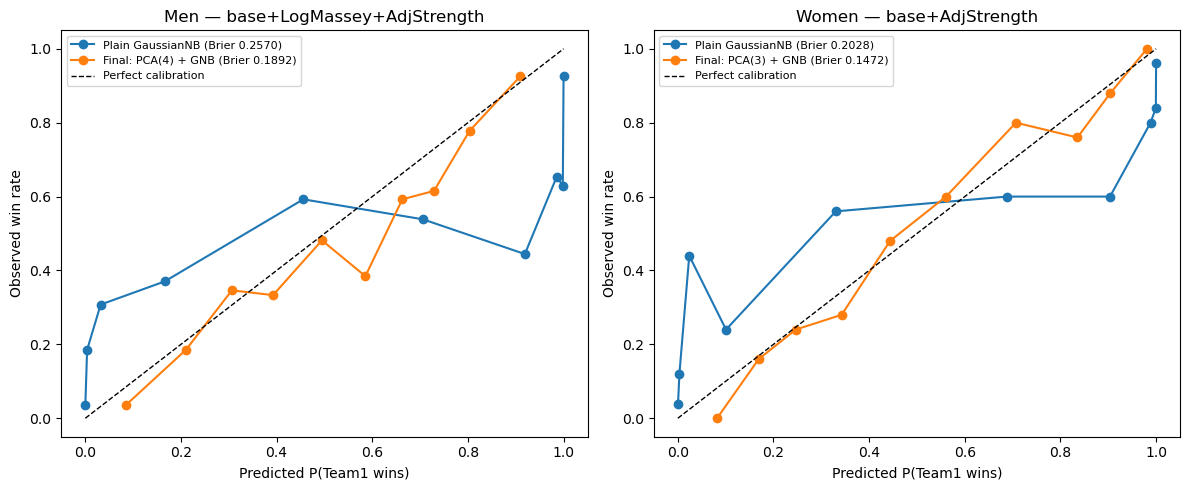

In [16]:
def oof_predictions(df, feats, make_model):
    parts = []
    for year in VALIDATION_YEARS:
        train, valid = df[df["Season"] < year], df[df["Season"] == year]
        m = make_model().fit(train[feats], train["Target"])
        parts.append(pd.DataFrame({"y": valid["Target"], "p": m.predict_proba(valid[feats])[:, 1]}))
    return pd.concat(parts)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, gender in zip(axes, ["men", "women"]):
    final_set, final_model = FINAL[gender]
    feats = ALL_SETS[gender][final_set]
    for label, factory in [("Plain GaussianNB", PLAIN["GaussianNB"]),
                           (f"Final: {final_model}", MODEL_FACTORIES[final_model])]:
        oof = oof_predictions(DATASETS[gender], feats, factory)
        frac_pos, mean_pred = calibration_curve(oof["y"], oof["p"], n_bins=10, strategy="quantile")
        ax.plot(mean_pred, frac_pos, marker="o",
                label=f"{label} (Brier {brier_score_loss(oof['y'], oof['p']):.4f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
    ax.set_title(f"{gender.capitalize()} — {final_set}")
    ax.set_xlabel("Predicted P(Team1 wins)")
    ax.set_ylabel("Observed win rate")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "nb_reliability.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Holdout 2022–2025 (run once, final configuration only)

Train on all seasons ≤ 2021, evaluate on 2022–2025. Per the README this holdout has been looked at repeatedly by the team, so treat it as a **diagnostic**, not for choosing features or settings. For comparison it also reports plain NB on the same feature set.

In [17]:
holdout_rows = []
for gender in ["men", "women"]:
    df = DATASETS[gender]
    final_set, final_model = FINAL[gender]
    feats = ALL_SETS[gender][final_set]
    train = df[df["Season"] <= 2021]
    test = df[df["Season"].isin(HOLDOUT_YEARS)]
    configs = [
        (SINGLE_BASELINE[gender], ALL_SETS[gender][SINGLE_BASELINE[gender]], "GaussianNB (single-feature baseline)", PLAIN["GaussianNB"]),
        (final_set, feats, "Plain GaussianNB", PLAIN["GaussianNB"]),
        (final_set, feats, final_model + " (final)", MODEL_FACTORIES[final_model]),
    ]
    for set_name, f, label, factory in configs:
        m = factory().fit(train[f], train["Target"])
        p = m.predict_proba(test[f])[:, 1]
        row = {"Gender": gender, "FeatureSet": set_name, "Model": label,
               "Overall": brier_score_loss(test["Target"], p)}
        for y in HOLDOUT_YEARS:
            mask = (test["Season"] == y).values
            row[y] = brier_score_loss(test["Target"][mask], p[mask])
        holdout_rows.append(row)

holdout = pd.DataFrame(holdout_rows).round(4)
holdout.to_csv(RESULTS / "naive_bayes_holdout.csv", index=False)
holdout

,Gender,FeatureSet,Model,Overall,2022,2023,2024,2025
0,men,LogMasseyRankDiff only,GaussianNB (single-feature baseline),0.1930,0.2186,0.2220,0.1900,0.1412
1,men,base+LogMassey+AdjStrength,Plain GaussianNB,0.2470,0.3262,0.2424,0.2564,0.1630
2,men,base+LogMassey+AdjStrength,PCA(4) + GNB (final),0.1960,0.2265,0.2143,0.1928,0.1504
3,women,SeedDiff only,GaussianNB (single-feature baseline),0.1484,0.1779,0.1773,0.1168,0.1218
4,women,base+AdjStrength,Plain GaussianNB,0.1641,0.1492,0.1949,0.1784,0.1337
5,women,base+AdjStrength,PCA(3) + GNB (final),0.1451,0.1663,0.1684,0.1245,0.1210


## Notes for the report

- **Motivation (convincingness):** NB's independence assumption is violated by our correlated strength features (see heatmap). Evidence: adding features *hurts* plain NB, and a single feature beats the full set.
- **Ablations:** calibration (Section 5) and PCA decorrelation (Section 6) each target that one failure mode; compare against plain NB on the same feature sets.
- **Single-feature baseline:** a one-feature NB (LogMassey for men, Seed for women) is a very strong, simple baseline — worth reporting honestly next to the multi-feature PCA model, and it is also evidence that most of the signal is shared across features.
- **Reliability diagram:** shows the overconfidence directly and how the final configuration fixes it.
- **Next step for Kaggle:** predictions for 2026 need the same features built for every possible 2026 matchup (not yet in the repo). Once that file exists, fit the final config on all seasons ≤ 2025 and call `predict_proba` on it.

Saved outputs in `results/`: `naive_bayes_cv_results.csv`, `naive_bayes_summary_table.csv`, `naive_bayes_holdout.csv`, `nb_feature_correlation.png`, `nb_reliability.png`.